# Improving Neural Network Learning

Training a neural network involves more than just running gradient descent. Several techniques can dramatically affect how fast the network learns, how well it generalises to unseen data, and whether it gets stuck or diverges.

This notebook explores the most important ones using a **synthetic regression dataset** built from a combination of trigonometric and logarithmic functions with added Gaussian noise.

Explore alternatives of gradient descents.

## 1. Synthetic Dataset

Import the required libraries:

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Generate 1000 evenly-spaced points over $[0, 4\pi]$ and compute the target function:

$$y_{\text{true}}(x) = \sin(x) + 0.5\cos(2x) + 0.3\ln(x+1)$$

Then add Gaussian noise $\varepsilon \sim \mathcal{N}(0,\, 0.2^2)$ to simulate real-world measurements:

$$y_{\text{noisy}}(x) = y_{\text{true}}(x) + \varepsilon$$

In [23]:
np.random.seed(42)

x       = np.linspace(0, 4 * np.pi, 1000)
y_true  = np.sin(x) + 0.5 * np.cos(2 * x) + 0.3 * np.log(x + 1)
noise   = np.random.normal(0, 0.2, size=x.shape)
y_noisy = y_true + noise

df = pd.DataFrame({'x': x, 'y_true': y_true, 'y_noisy': y_noisy})
df.head()

,x,y_true,y_noisy
0,0.000000,0.500000,0.599343
1,0.012579,0.516171,0.488518
2,0.025158,0.531976,0.661514
3,0.037737,0.547417,0.852023
4,0.050316,0.562492,0.515662


Visualise the clean target function and the noisy observations:

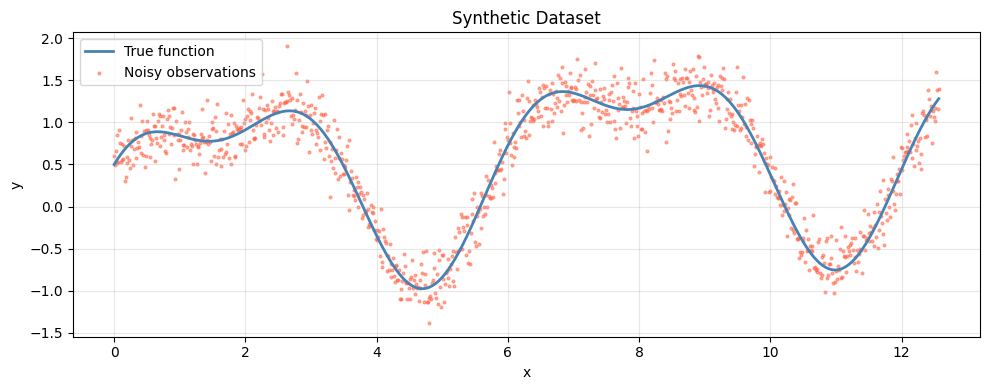

In [24]:
plt.figure(figsize=(10, 4))
plt.plot(df['x'], df['y_true'],  color='steelblue', linewidth=2, label='True function')
plt.scatter(df['x'], df['y_noisy'], color='tomato', s=4, alpha=0.5, label='Noisy observations')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Synthetic Dataset')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## 2. Train / Validation / Test Split

Before training, split the data into three sets:

| Set | Purpose | Size |
|:----|:--------|-----:|
| **Train** | update weights | 70 % |
| **Validation** | monitor generalisation during training | 15 % |
| **Test** | final unbiased evaluation | 15 % |

The split is done on the shuffled index so that all three sets cover the full range of $x$.

Its impossible to get all your hyperparameters right on a new application from the first time. So the idea is you go through the loop: Idea ==> Code ==> Experiment. <br>
You have to go through the loop many times to figure out your hyperparameters. You will try to build a model upon training set then try to optimize hyperparameters on validation set as much as possible. Then after your model is ready you try and evaluate the testing set. So the trend on the ratio of splitting the models:
If size of the dataset is 100 to 1000000 ==> 70/15/15
If size of the dataset is 1000000 to INF ==> 98/1/1 or 99.5/0.25/0.25
The trend now gives the training data the biggest sets.

In [25]:
from sklearn.model_selection import train_test_split

X = df[['x']].values
y = df['y_noisy'].values.reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val,   X_test,  y_val,  y_test  = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f'Train: {X_train.shape[0]}  |  Val: {X_val.shape[0]}  |  Test: {X_test.shape[0]}')

Train: 700  |  Val: 150  |  Test: 150


## 3. Input Normalisation

The input $x$ spans $[0,\, 4\pi] \approx [0,\, 12.6]$. Feeding raw values of this magnitude into a network with small random weights produces very large pre-activations, which saturate sigmoid/tanh neurons and slow down learning.

**Standard score normalisation** rescales each feature to have zero mean and unit variance:

$$x_{\text{norm}} = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

The statistics ($\mu$, $\sigma$) are computed **on the training set only** and then applied to validation and test sets — this prevents information from leaking into the model.

In [26]:
mu    = X_train.mean()
sigma = X_train.std()

X_train_n = (X_train - mu) / sigma
X_val_n   = (X_val   - mu) / sigma
X_test_n  = (X_test  - mu) / sigma

print(f'Train mean: {X_train_n.mean():.4f}  std: {X_train_n.std():.4f}')

Train mean: -0.0000  std: 1.0000


## 4. Baseline Network

A fully-connected network with two hidden layers and **ReLU** activations. The output layer is linear (no activation) since this is a regression task.

Architecture: $1 \to 32 \to 32 \to 1$

In [27]:
def relu(z):      
    return np.maximum(0, z)

def relu_deriv(z):  
    return (z > 0).astype(float)

**He initialisation** sets the initial weights by drawing from $\mathcal{N}\!\left(0,\, \sqrt{2/n_{\text{in}}}\right)$, which keeps the variance of activations stable across layers when using ReLU.

In [28]:
def init_params(layer_sizes, seed=0):
    np.random.seed(seed)
    params = {}
    for i in range(1, len(layer_sizes)):
        fan_in = layer_sizes[i - 1]
        params[f'W{i}'] = np.random.randn(fan_in, layer_sizes[i]) * np.sqrt(2 / fan_in)
        params[f'b{i}'] = np.zeros((1, layer_sizes[i]))
    return params

layer_sizes = [1, 32, 32, 1]
params = init_params(layer_sizes)
print({k: v.shape for k, v in params.items()})

{'W1': (1, 32), 'b1': (1, 32), 'W2': (32, 32), 'b2': (1, 32), 'W3': (32, 1), 'b3': (1, 1)}


**Forward pass** — propagate the input through each layer:

$$z^{(l)} = a^{(l-1)} \cdot W^{(l)} + b^{(l)}, \qquad a^{(l)} = \text{ReLU}(z^{(l)})$$

The output layer has no activation: $\hat{y} = z^{(L)}$.

In [29]:
def forward(X, params):
    cache = {'a0': X}
    a = X
    n_layers = len(params) // 2

    for i in range(1, n_layers):        # hidden layers — ReLU
        z = a @ params[f'W{i}'] + params[f'b{i}']
        a = relu(z)
        cache[f'z{i}'] = z
        cache[f'a{i}'] = a

    i = n_layers                        # output layer — linear
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = z
    cache[f'a{i}'] = z
    
    return z, cache

**Backward pass** — compute gradients via the chain rule.

Output layer (linear activation):
$$\delta^{(L)} = -(y - \hat{y})$$

Hidden layer $l$ (ReLU):
$$\delta^{(l)} = \left(\delta^{(l+1)} \cdot W^{(l+1)T}\right) \odot \text{ReLU}'(z^{(l)})$$

Weight gradients:
$$\frac{\partial J}{\partial W^{(l)}} = a^{(l-1)T} \cdot \delta^{(l)}, \qquad \frac{\partial J}{\partial b^{(l)}} = \sum \delta^{(l)}$$

In [30]:
def backward(y, y_hat, params, cache):
    m = y.shape[0]
    grads = {}
    n_layers = len(params) // 2
    delta = -(y - y_hat) / m

    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)

        if i > 1:
            delta = delta @ params[f'W{i}'].T * relu_deriv(cache[f'z{i-1}'])
            
    return grads

Update each weight matrix with the standard gradient descent rule: $W \leftarrow W - \alpha \cdot \nabla_W J$

In [31]:
def update_params(params, grads, lr):
    for key in params:
        params[key] -= lr * grads['d' + key]
        
    return params

**Mean Squared Error** loss:

$$J = \frac{1}{m} \sum_{i=1}^{m} (y_i - \hat{y}_i)^2$$

In [32]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

## 5. Training the Baseline

Train for a fixed number of epochs using full-batch gradient descent. Both training and validation loss are recorded at every epoch to detect overfitting.

In [33]:
import time

def train(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)
        params       = update_params(params, grads, lr)
        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _   = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_base, tl_base, vl_base, t_base = train(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, epochs=2000
)

Final train MSE: 0.2857  |  val MSE: 0.2486  |  time: 0.69s


Plot training and validation loss curves to check for overfitting:

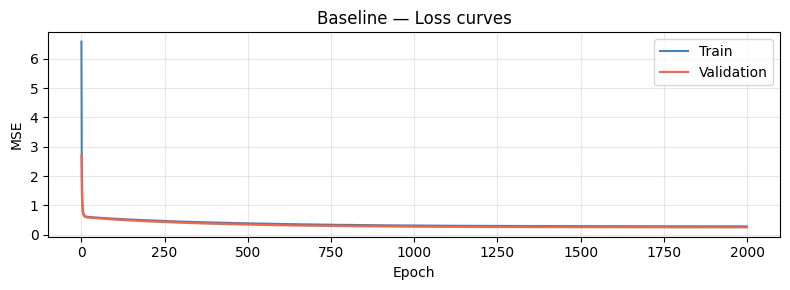

In [34]:
def plot_loss(train_loss, val_loss, title='Loss curves'):
    plt.figure(figsize=(8, 3))
    plt.plot(train_loss, label='Train',      color='steelblue')
    plt.plot(val_loss,   label='Validation', color='tomato')
    plt.xlabel('Epoch'); plt.ylabel('MSE')
    plt.title(title); plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

plot_loss(tl_base, vl_base, title='Baseline — Loss curves')

# MiniBatch Gradient Descent

We just learned how gradient descent works. In gradient descent, to perform a single
parameter update we iterate through all the data points in our training set. Updating the parameters of the model only after iterating through all the data points in the training set makes the gradient descent very slow and it will increase the training time
especially when we have a large dataset. 


So, we use minibatch gradient descent, in minibatch gradient descent, we update the parameters after iterating some batch of data points. Let us say the batch size is 50
which means that we update the parameter of the model after iterating through 50 data
points instead of updating the parameter after iterating through each individual data point.

Guidelines for choosing mini-batch size:
- If small training set (< 2000 examples) - use batch gradient descent.
- It has to be a power of 2 (because of the way computer memory is layed out and accessed, sometimes your code runs faster if your mini-batch size is a power of 2): 64, 128, 256, 512, 1024, ... Make sure that mini-batch fits in CPU/GPU memory.

Mini-batch size is a hyperparameter.

In [ ]:
def minibatch_gd(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, batch_size=32, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []
    m = X_tr.shape[0]

    start = time.time()
    
    for _ in range(epochs):
        idx = np.random.permutation(m)
        X_shuffled = X_tr[idx]
        y_shuffled = y_tr[idx]

        for s in range(0, m, batch_size):
            X_batch = X_shuffled[s : s + batch_size]
            y_batch = y_shuffled[s : s + batch_size]
            y_hat, cache = forward(X_batch, params)
            grads        = backward(y_batch, y_hat, params, cache)
            params       = update_params(params, grads, lr)

        y_hat_tr, _ = forward(X_tr, params)
        y_hat_v,  _ = forward(X_v,  params)
        train_loss.append(mse(y_tr, y_hat_tr))
        val_loss.append(mse(y_v,  y_hat_v))

    end = time.time()
    elapsed = end - start

    return params, train_loss, val_loss, elapsed

Final train MSE: 0.0411  |  val MSE: 0.0426  |  time: 2.31s


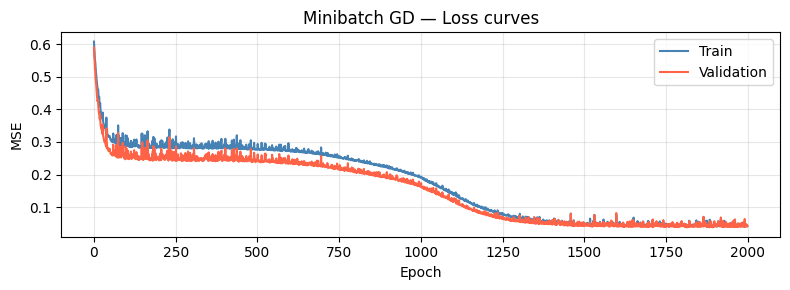

In [36]:
params_mb, tl_mb, vl_mb, t_mb = minibatch_gd(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1]
)

print(f'Final train MSE: {tl_mb[-1]:.4f}  |  val MSE: {vl_mb[-1]:.4f}  |  time: {t_mb:.2f}s')

plot_loss(tl_mb, vl_mb, title='Minibatch GD — Loss curves')

### Comparison with other techniques

Given "m" the number of sample in the training set, we have:

- (mini batch size = m) ==> Batch gradient descent
- (mini batch size = 1) ==> Stochastic gradient descent (SGD)
- (mini batch size = between 1 and m) ==> Mini-batch gradient descent

In mini-batch algorithm, the cost won't go down with each step as it does in batch algorithm. It could contain some ups and downs but generally it has to go down (unlike the batch gradient descent where cost function descreases on each iteration). 

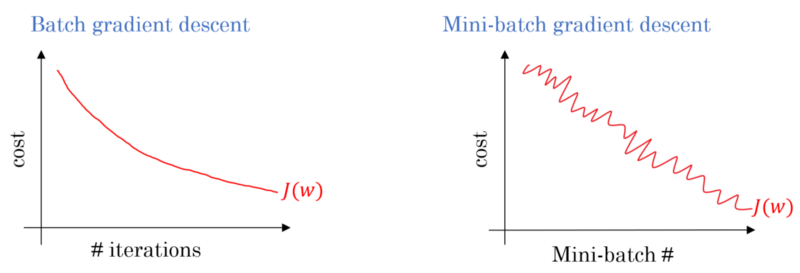

- Batch gradient descent: too long per iteration (epoch)
- Stochastic gradient descent:
    - too noisy regarding cost minimization (can be reduced by using smaller learning rate)
    - won't ever converge (reach the minimum cost)
    - lose speedup from vectorization
- Mini-batch gradient descent:
    - faster learning (you have the vectorization advantage)
    - make progress without waiting to process the entire training set
    - doesn't always exactly converge (oscelates in a very small region, but you can reduce learning rate)

# Exponentially weighted averages

There are optimization algorithms that are better than gradient descent, but you should first learn about Exponentially weighted averages.
If we have data like the temperature of day through the year it could be like this:

t(1) = 40 <br>
t(2) = 49 <br>
t(3) = 45 <br>
... <br>
t(180) = 60 <br>

If we plot this data we will find it some noisy. Now lets compute the Exponentially weighted averages:

V0 = 0 <br>
V1 = 0.9 * V0 + 0.1 * t(1) = 4		# 0.9 and 0.1 are hyperparameters <br>
V2 = 0.9 * V1 + 0.1 * t(2) = 8.5 <br>
V3 = 0.9 * V2 + 0.1 * t(3) = 12.15 <br>

We can implement this algorithm with more accurate results using a moving window. But the code is more efficient and faster using the exponentially weighted averages algorithm. General equation: <br>
$V(t) = \beta * v(t-1) + (1- \beta) * \theta(t)$ <br>

represent averages over ~ $\frac{1} {1 - \beta}$ entries:

$\beta$ = 0.9 will average last 10 entries <br>
$\beta$ = 0.98 will average last 50 entries <br>
$\beta$ = 0.5 will average last 2 entries <br>

**Intuition**: The reason why exponentially weighted averages are useful for further optimizing gradient descent algorithm is that it can give different weights to recent data points (theta) based on value of beta. If beta is high (around 0.9), it smoothens out the averages of skewed data points (oscillations w.r.t. Gradient descent terminology). So this reduces oscillations in gradient descent and hence makes faster and smoother path towerds minima.

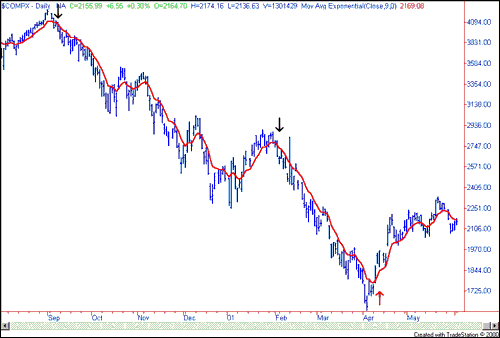

### Bias correction in exponentially weighted averages

The bias correction helps make the exponentially weighted averages more accurate. Because v(0) = 0, the bias of the weighted averages is shifted and the accuracy suffers at the start. To solve the bias issue we have to use this equation: <br>

$v(t) = \frac {\beta v(t-1) + (1- \beta) \theta(t)} {1 - \beta^t}$

As t becomes larger the $(1 - \beta^t)$ becomes close to 1

# Gradient descent with Momentum

The simple idea is to calculate the exponentially weighted averages for your gradients and then update your weights with the new values.
We learned how momentum helps us to reduce oscillations in the gradient steps and attain the convergence faster. The update equation of momentum is given as:

$$v_t = \gamma v_{t-1} + \eta \nabla_\theta J( \theta) $$

Update theta by: 
$${\theta = \theta - v_t } $$

$\gamma$ = 0.9 is very common and works very well in most cases. In practice people don't bother implementing bias correction.


Final train MSE: 0.1201  |  val MSE: 0.0972  |  time: 0.66s


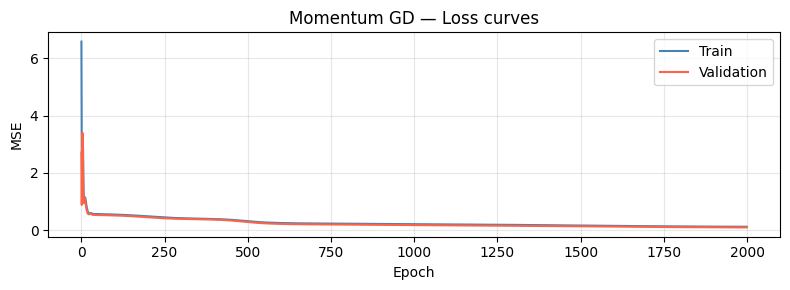

In [37]:
def momentum_gd(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, gamma=0.9, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            vt[key]     = gamma * vt[key] + lr * grads['d' + key]
            params[key] = params[key] - vt[key]

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_mom, tl_mom, vl_mom, t_mom = momentum_gd(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, gamma=0.9, epochs=2000
)
plot_loss(tl_mom, vl_mom, title='Momentum GD — Loss curves')

# Nesterov accelerated gradients

Refer the NAG section in the book for the detailed explanation.

The update equation of NAG is given as:

$$v_t = \gamma v_{t-1} + \eta \nabla_\theta J( \theta - \gamma v_{t-1} ) $$

Update theta by:
$${\theta = \theta - v_t } $$

Final train MSE: 0.0557  |  val MSE: 0.0460  |  time: 0.68s


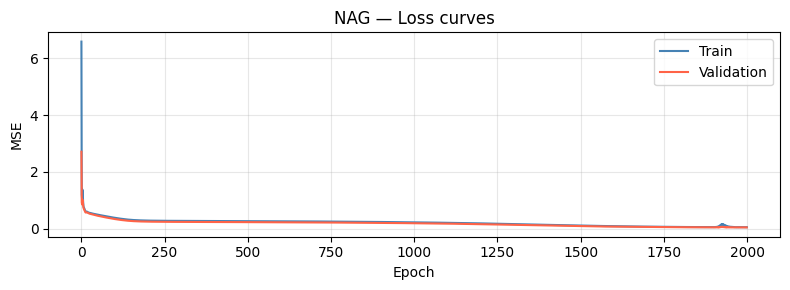

In [38]:
def nag(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, gamma=0.9, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        # look-ahead: evaluate gradient at the anticipated future position
        params_ahead = {key: params[key] - gamma * vt[key] for key in params}

        y_hat, cache = forward(X_tr, params_ahead)
        grads        = backward(y_tr, y_hat, params_ahead, cache)

        for key in params:
            vt[key]     = gamma * vt[key] + lr * grads['d' + key]
            params[key] = params[key] - vt[key]

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_nag, tl_nag, vl_nag, t_nag = nag(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, gamma=0.9, epochs=2000
)
plot_loss(tl_nag, vl_nag, title='NAG — Loss curves')

# Set Learning rate adaptively using AdaGrad 

In a nutshell, in AdaGrad, we set the learning rate to a small value when past gradients
value is high and to a high value when the past gradient value is less. So our learning rate
value changes according to the past gradients updates of the parameter.(Refer the section AdaGrad in the book for a detailed explanation)

The update equation of Adagrad is given as:


$${\theta_{t}^i = \theta_{t-1}^i - \dfrac{\eta}{\sqrt{ \sum_{\tau=1}^t (g_{\tau}^i)^2   + \epsilon}} \cdot g_{t}^i } $$

Final train MSE: 0.1568  |  val MSE: 0.1309  |  time: 0.68s


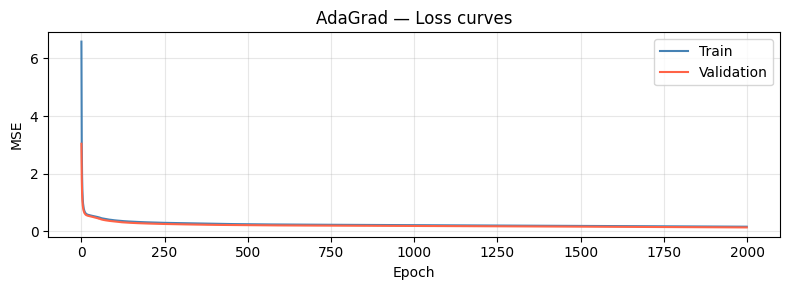

In [39]:
def adagrad(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epsilon=1e-8, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    grad_sq = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            grad_sq[key] += grads['d' + key] ** 2
            params[key]  -= lr * grads['d' + key] / (np.sqrt(grad_sq[key]) + epsilon)

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_ada, tl_ada, vl_ada, t_ada = adagrad(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, epsilon=1e-8, epochs=2000
)
plot_loss(tl_ada, vl_ada, title='AdaGrad — Loss curves')

# Do away with Learning rate using Adadelta 


With AdaDelta we completely get rid of learning rate. (Refer the section AdaDelta in the book for full explanation)

The update equation of AdaDelta is expressed as:

Running average of gradients:
$$E\left[g^{2}\right]_{t}=\gamma E\left[g^{2}\right]_{t-1}+(1-\gamma) g_{t}^{2} $$

Compute delta:
$$ \nabla \theta_{t}=-\frac{R M S[\Delta \theta]_{t-1}}{R M S\left[g_{t}\right]} \cdot g_{t}^{i} $$

Running averge of parameter update:
$$ E\left[\Delta \theta^{2}\right]_{t}=\gamma E\left[\Delta \theta^{2}\right]_{t-1}+(1-\gamma) \Delta \theta_{t}^{2} $$

Update theta:
$$ \theta_{t}^{i}=\theta_{t-1}^{i}+\nabla \theta_{t} $$

Final train MSE: 0.0664  |  val MSE: 0.0628  |  time: 0.74s


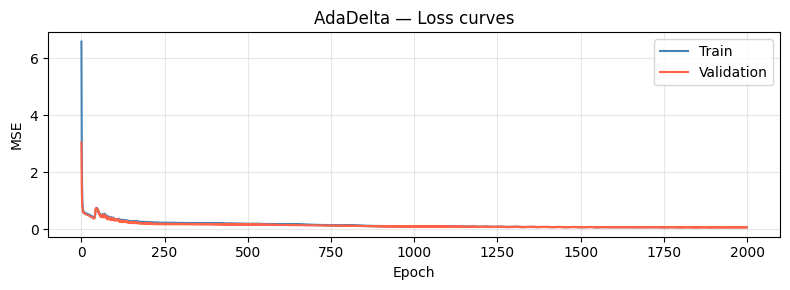

In [40]:
def adadelta(X_tr, y_tr, X_v, y_v, layer_sizes, gamma=0.9, epsilon=1e-5, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    E_grad2  = {key: np.zeros_like(val) for key, val in params.items()}
    E_delta2 = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g              = grads['d' + key]
            E_grad2[key]   = gamma * E_grad2[key] + (1 - gamma) * g ** 2
            delta          = -(np.sqrt(E_delta2[key] + epsilon)) / (np.sqrt(E_grad2[key] + epsilon)) * g
            E_delta2[key]  = gamma * E_delta2[key] + (1 - gamma) * delta ** 2
            params[key]   += delta

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_adad, tl_adad, vl_adad, t_adad = adadelta(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], gamma=0.9, epsilon=1e-5, epochs=2000
)
plot_loss(tl_adad, vl_adad, title='AdaDelta — Loss curves')

# Overcoming limitations of AdaGrad using RMSProp

We learned that in AdaGrad learning rate would become very small when the sum of gradients is high. So, we RMSProp to overcome the limitations of RMSProp. Stands for Root mean square prop. With RMSprop you can increase your learning rate.

The update equation of RMSProp is given as:

Running average of gradients:
$$E\left[g^{2}\right]_{t}=\gamma E\left[g^{2}\right]_{t-1}+(1-\gamma) g_{t}^{2} $$

Update theta:
$$\theta_{t}^{i}=\theta_{t-1}^{i}-\frac{\eta}{\sqrt{E\left[g^{2}\right]_{t}+\epsilon}} \cdot g_{t}^{i} $$

Final train MSE: 0.0541  |  val MSE: 0.0840  |  time: 0.74s


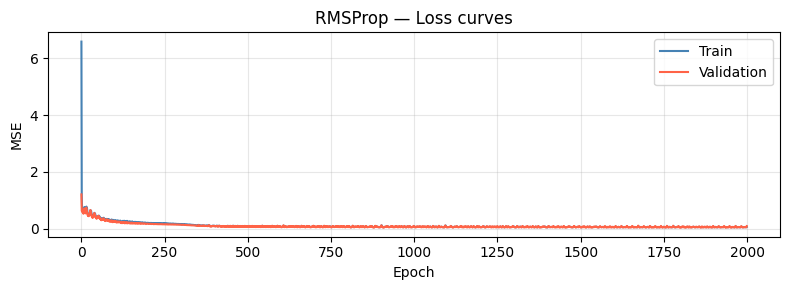

In [41]:
def rmsprop(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, gamma=0.9, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    E_grad2 = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g             = grads['d' + key]
            E_grad2[key]  = gamma * E_grad2[key] + (1 - gamma) * g ** 2
            params[key]  -= lr / (np.sqrt(E_grad2[key]) + epsilon) * g

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_rms, tl_rms, vl_rms, t_rms = rmsprop(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, gamma=0.9, epsilon=1e-6, epochs=2000
)
plot_loss(tl_rms, vl_rms, title='RMSProp — Loss curves')

# Adam - Adaptive Moment Estimation

Adam optimization and RMSprop are among the optimization algorithms that worked very well with a lot of NN architectures. Adam optimization simply puts RMSprop and momentum together! The update equation of Adam is given as:

First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t} $$

Second moment estimate:
$$v_{t}=\beta_{2} v_{t-1}+\left(1-\beta_{2}\right) g_{t}^{2} $$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m_{t}}{1-\beta_{1}^{t}} $$

Bias-corrected vt:
$$\hat{v}_{t}=\frac{v_{t}}{1-\beta_{2}^{t}} $$

Update theta:

$$\theta_{t}=\theta_{t-1}-\frac{\eta}{\sqrt{\hat{v}_{t}}+\epsilon} \hat{m}_{t} $$

Hyperparameters for Adam:
- $\eta$: needed to be tuned.
- $\beta_1$: parameter of the momentum - 0.9 is recommended by default.
- $\beta_2$: parameter of the RMSprop - 0.999 is recommended by default.
- $\epsilon$: 10^-8 is recommended by default.

Final train MSE: 0.0408  |  val MSE: 0.0392  |  time: 0.77s


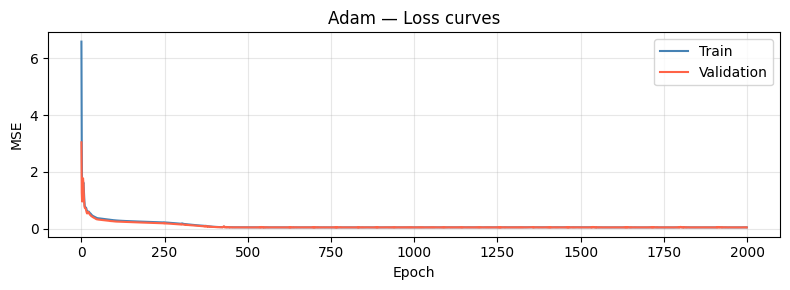

In [42]:
def adam(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt = {key: np.zeros_like(val) for key, val in params.items()}
    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g       = grads['d' + key]
            mt[key] = beta1 * mt[key] + (1 - beta1) * g
            vt[key] = beta2 * vt[key] + (1 - beta2) * g ** 2
            mt_hat  = mt[key] / (1 - beta1 ** t)
            vt_hat  = vt[key] / (1 - beta2 ** t)
            params[key] -= lr / (np.sqrt(vt_hat) + epsilon) * mt_hat

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_adam, tl_adam, vl_adam, t_adam = adam(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_adam, vl_adam, title='Adam — Loss curves')

# Adamax - Adam based on infinity norm


Check the section Adamax in the book for the detailed explanation. The update equation of Adamax is given as:

First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t} $$

Second moment estimate:
$$v_{t}=\max \left(\beta_{2} \cdot v_{t-1},\left|g_{t}\right|\right) $$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m_{t}}{1-\beta_{1}^{t}} $$

Update theta:

$$\theta_{t}=\theta_{t-1}-\frac{\eta}{v_{t}} \hat{m}_{t} $$


Final train MSE: 0.0379  |  val MSE: 0.0362  |  time: 0.73s


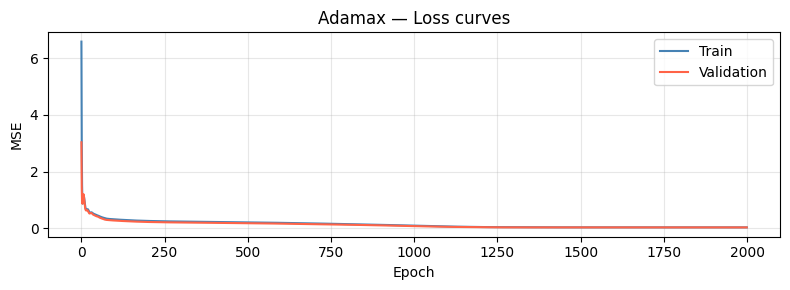

In [43]:
def adamax(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt = {key: np.zeros_like(val) for key, val in params.items()}
    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g       = grads['d' + key]
            mt[key] = beta1 * mt[key] + (1 - beta1) * g
            mt_hat  = mt[key] / (1 - beta1 ** t)
            vt[key] = np.maximum(beta2 * vt[key], np.abs(g))
            params[key] -= (lr / (vt[key] + epsilon)) * mt_hat

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_amax, tl_amax, vl_amax, t_amax = adamax(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_amax, vl_amax, title='Adamax — Loss curves')

# Adaptive Moment Estimation with AMSGrad


Refer the section AMSGrad in the book for the detailed explanation. The update equation of AMSGrad is given as:

First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t} $$

Second moment estimate:
$$v_{t}=\beta_{2} v_{t-1}+\left(1-\beta_{2}\right) g_{t}^{2} $$

Updated second moment estimate:
$$\hat{v}_{t}=\max \left(\hat{v}_{t-1}, v_{t}\right)$$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m t}{1-\beta_{1}^{t}} $$

Update theta:
$$\theta_{t}=\theta_{t-1}-\frac{\eta}{\sqrt{\hat{v}_{t}}+\epsilon} \hat{m}_{t} $$

Final train MSE: 0.0500  |  val MSE: 0.0441  |  time: 0.82s


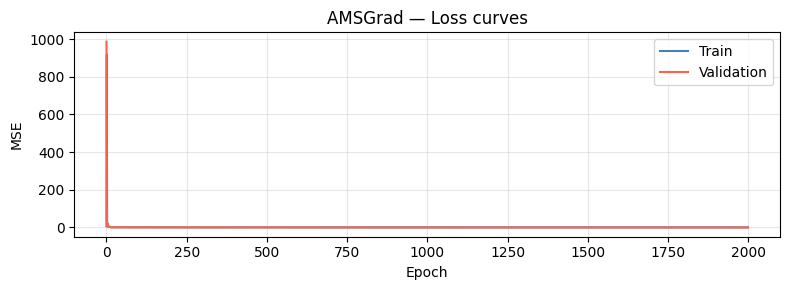

In [44]:
def amsgrad(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt     = {key: np.zeros_like(val) for key, val in params.items()}
    vt     = {key: np.zeros_like(val) for key, val in params.items()}
    vt_hat = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g           = grads['d' + key]
            mt[key]     = beta1 * mt[key] + (1 - beta1) * g
            vt[key]     = beta2 * vt[key] + (1 - beta2) * g ** 2
            vt_hat[key] = np.maximum(vt_hat[key], vt[key])
            mt_hat      = mt[key] / (1 - beta1 ** t)
            params[key] -= lr / (np.sqrt(vt_hat[key]) + epsilon) * mt_hat

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_ams, tl_ams, vl_ams, t_ams = amsgrad(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_ams, vl_ams, title='AMSGrad — Loss curves')

# Nadam - Adding NAG to ADAM


Refer the section Nadam in the book for the detailed explanation. The update equation of Nadam is given as:


First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t}  $$

Second moment estimate:
$$v_{t}=\beta_{2} v_{t-1}+\left(1-\beta_{2}\right) g_{t}^{2} $$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m_{t}}{1-\prod_{i=1}^{t+1} \beta_{1}^{i}}  $$

Bias-corrected gt:
$$\hat{g}_{t}=\frac{g_{t}}{1-\prod_{i=1}^{t} \beta_{1}^{i}} $$

Bias-corrected vt:
$$ \hat{v}_{t}=\frac{v_{t}}{1-\beta_{2}^{t}} $$

Compute m tilde:
$$ \tilde{m}_{t}=\beta_{1}^{t+1} \hat{m}_{t}+\left(1-\beta_{1}^{t}\right) \hat{g}_{t} $$

Update theta:
$$ \theta_{t}=\theta_{t-1}-\frac{\eta}{\sqrt{v_{t}}+\epsilon} \tilde{m}_{t}  $$

Final train MSE: 0.0419  |  val MSE: 0.0451  |  time: 0.78s


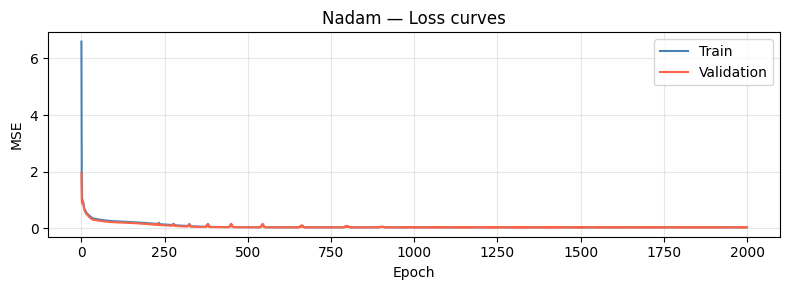

In [45]:
def nadam(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt         = {key: np.zeros_like(val) for key, val in params.items()}
    vt         = {key: np.zeros_like(val) for key, val in params.items()}
    beta1_prod = 1.0

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        beta1_prod *= beta1

        for key in params:
            g        = grads['d' + key]
            mt[key]  = beta1 * mt[key] + (1 - beta1) * g
            vt[key]  = beta2 * vt[key] + (1 - beta2) * g ** 2
            mt_hat   = mt[key] / (1 - beta1_prod * beta1)
            g_hat    = g       / (1 - beta1_prod)
            vt_hat   = vt[key] / (1 - beta2 ** t)
            mt_tilde = beta1 * mt_hat + (1 - beta1) * g_hat
            params[key] -= lr / (np.sqrt(vt_hat) + epsilon) * mt_tilde

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_nadam, tl_nadam, vl_nadam, t_nadam = nadam(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_nadam, vl_nadam, title='Nadam — Loss curves')